In [80]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import arviz as az
import cmdstanpy
from cmdstanpy import CmdStanModel

cmdstanpy.set_cmdstan_path(os.path.expanduser("~/cmdstan"))

from scipy.special import expit as inv_logit, logit
import networkx as nx

np.random.seed(6300)

In [81]:
policy_metadata = pd.read_csv('./policy-metadata.csv')
policy_metadata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 645125 entries, 0 to 645124
Data columns (total 27 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Unnamed: 0      645125 non-null  int64  
 1   hash            645125 non-null  object 
 2   year            645125 non-null  int64  
 3   month           645125 non-null  int64  
 4   timestamp       645125 non-null  int64  
 5   uri             645125 non-null  object 
 6   rank            626688 non-null  float64
 7   flesch          645125 non-null  float64
 8   cl              645125 non-null  float64
 9   smog            645125 non-null  float64
 10  wordcount       645125 non-null  float64
 11  sentencecount   645125 non-null  float64
 12  syllablecount   645125 non-null  float64
 13  count_ccpa      645125 non-null  int64  
 14  count_dnt       645125 non-null  int64  
 15  count_gdpr      645125 non-null  int64  
 16  count_p3p       645125 non-null  int64  
 17  count_priv

In [82]:
data = policy_metadata[['policyid', 'wordcount', 'sentencecount', 'numobfs', 'numpassive', 'flesch']]
data.head()

,policyid,wordcount,sentencecount,numobfs,numpassive,flesch
0,4695,2182.0,77.0,201.0,14.0,31.437442
1,4695,2182.0,77.0,201.0,14.0,31.437442
2,4695,2182.0,77.0,201.0,14.0,31.437442
3,4695,2182.0,77.0,201.0,14.0,31.437442
4,4695,2182.0,77.0,201.0,14.0,31.437442


In [83]:
from pathlib import Path
stan_code = r"""
data {
  int<lower=1> N;
  int<lower=2> K;
  matrix[N, K] X;
  vector[N] y;
  real alpha_mean;
  real<lower=0> alpha_sd;
  real<lower=0> beta_sd;
}
parameters {
  vector[K] beta;
  real<lower=0> sigma;
}
model {
  beta[1] ~ normal(alpha_mean, alpha_sd);
  beta[2:K] ~ normal(0, beta_sd);
  sigma ~ exponential(1);
  y ~ normal_id_glm(X, 0, beta, sigma);
}
"""
stan_path = Path("linear_regression.stan")
stan_path.write_text(stan_code)
regression_model = CmdStanModel(stan_file=str(stan_path))

regression_model = CmdStanModel(stan_file=str(stan_path))

def dag(edges, pos=None):
    graph = nx.DiGraph(edges)
    if pos is None:
        pos = nx.spring_layout(graph, seed=6)
    plt.figure(figsize=(4, 3))
    nx.draw_networkx(graph, pos, node_color="white", edgecolors="black",
                     node_size=860, arrowsize=22, font_size=12)
    plt.axis("off")
    plt.show()
    return graph

def norm(n, mu=0, sigma=1):
    """Normal draws."""
    return np.random.normal(mu, sigma, size=n)

def corr(x, y):
    """Pearson correlation."""
    return np.corrcoef(x, y)[0, 1]

def regress(y, X, alpha_sd=1, beta_sd=1, alpha_mean=0, **sample_kwargs):
    """Regress y on x with Stan. Takes care of shaping the design matrix."""
    y, X = np.asarray(y, dtype=float), np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X[:, None]
    design = np.column_stack([np.ones(len(y)), X])
    data = dict(N=len(y), K=design.shape[1], X=design, y=y,
                alpha_mean=alpha_mean, alpha_sd=alpha_sd, beta_sd=beta_sd)
    options = dict(chains=2, parallel_chains=2, iter_warmup=500,
                   iter_sampling=1000, seed=6300, inits=0, step_size=0.01,
                   show_progress=False)
    options.update(sample_kwargs)
    return regression_model.sample(data=data, **options)


08:48:52 - cmdstanpy - INFO - compiling stan file /Users/marobinette/bayesian_statistics/portfolio/3/linear_regression.stan to exe file /Users/marobinette/bayesian_statistics/portfolio/3/linear_regression
08:49:03 - cmdstanpy - INFO - compiled model executable: /Users/marobinette/bayesian_statistics/portfolio/3/linear_regression


# Causal graph and question
- We are interested in the Tranco ranking of a website as the outcome, noted as R in our DAG.
- We want to know the effect of intervention on number of obfuscationg words. Specifically, does
- decreasing the number of obfuscating words in a privacy policy improve the Tranco rankiing of a site?

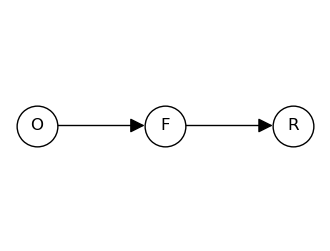

In [ ]:
dag([("O", "F"), ("F", "R")], {"O": (-1, 0), "F": (0, 0), "R": (1, 0)});

# 3 Fake-data model

In [91]:
np.random.seed(6300)
n = 1425
O_sim = norm(n, 0, 1)
F_sim = norm(n, -0.5 * O_sim, np.sqrt(0.75))
R_sim = norm(n, -0.4 * F_sim, np.sqrt(0.84))

print("corr(O, F):", round(corr(O_sim, F_sim), 3))
print("corr(F, R):", round(corr(F_sim, R_sim), 3))
print("corr(O, R):", round(corr(O_sim, R_sim), 3))

corr(O, F): -0.478
corr(F, R): -0.422
corr(O, R): 0.206


In [ ]:
fit1 = regress(R_sim, O_sim, alpha_sd=0.2, beta_sd=0.5)   # Model 1: R ~ O
fit2 = regress(R_sim, np.column_stack([O_sim, F_sim]), alpha_sd=0.2, beta_sd=0.5)   # Model 2: R ~ O + F

08:49:04 - cmdstanpy - INFO - CmdStan start processing
08:49:04 - cmdstanpy - INFO - Chain [1] start processing
08:49:04 - cmdstanpy - INFO - Chain [2] start processing
08:49:04 - cmdstanpy - INFO - Chain [1] done processing
08:49:04 - cmdstanpy - INFO - Chain [2] done processing
08:49:04 - cmdstanpy - INFO - CmdStan start processing
08:49:04 - cmdstanpy - INFO - Chain [1] start processing
08:49:04 - cmdstanpy - INFO - Chain [2] start processing
08:49:04 - cmdstanpy - INFO - Chain [1] done processing
08:49:04 - cmdstanpy - INFO - Chain [2] done processing


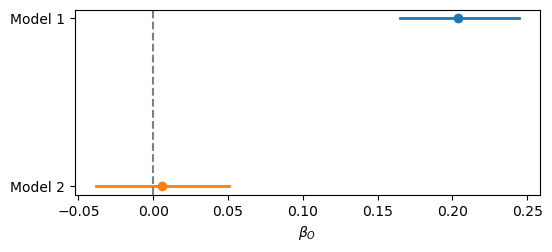

In [88]:
plt.figure(figsize=(6, 2.4))
for row, (label, fit) in enumerate([("Model 1", fit1), ("Model 2", fit2)]):
    b = fit.stan_variable("beta")[:, 1]
    lo, hi = np.quantile(b, [0.05, 0.95])
    plt.plot([lo, hi], [row, row], color=f"C{row}", lw=2)
    plt.plot(b.mean(), row, "o", color=f"C{row}")
plt.yticks([0, 1], ["Model 1", "Model 2"])
plt.gca().invert_yaxis()
plt.axvline(0, color="0.5", linestyle="--")
plt.xlabel(r"$\beta_O$")
plt.show()

In [ ]:
fit2.summary()


,Mean,MCSE,StdDev,MAD,5%,50%,95%,ESS_bulk,ESS_tail,ESS_bulk/s,R_hat
lp__,-590.837000,0.043020,1.389490,1.218930,-593.684000,-590.498000,-589.223000,1086.75,1423.75,4116.48,1.001570
beta[1],-0.034028,0.000530,0.024571,0.024200,-0.076560,-0.034320,0.006572,2127.54,1453.16,8058.88,1.000340
beta[2],0.006090,0.000593,0.026506,0.026316,-0.038330,0.005804,0.050783,2005.43,1576.58,7596.32,1.001370
beta[3],-0.424599,0.000627,0.027690,0.026943,-0.471114,-0.424579,-0.379611,1960.76,1434.83,7427.12,1.001170
sigma,0.917884,0.000375,0.017258,0.017420,0.889406,0.917849,0.946196,2128.64,1553.71,8063.01,0.999368
